In [1]:
"""Deploy and manage an automated machine learning (autoML) solution (e.g., H2O.ai, Google AutoML, Auto-sklearn) for continuous model improvement, hyperparameter tuning, and selection of optimal algorithms without manual intervention."""

'Deploy and manage an automated machine learning (autoML) solution (e.g., H2O.ai, Google AutoML, Auto-sklearn) for continuous model improvement, hyperparameter tuning, and selection of optimal algorithms without manual intervention.'

In [2]:
# import libraries and load pharmacy sales dataset for automl pipeline
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

data_path = 'global_pharmacy_sales_data.csv' if os.path.exists('global_pharmacy_sales_data.csv') else '../global_pharmacy_sales_data.csv'
df = pd.read_csv(data_path)
print("pharmacy sales dataset loaded for automl pipeline. shape:", df.shape)

pharmacy sales dataset loaded for automl pipeline. shape: (177990, 14)


In [3]:
# clean data and split into training and validation sets
sample_df = df.sample(n=5000, random_state=42).reset_index(drop=True)
features = ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'year', 'month', 'day']
target = 'units_sold'

X = sample_df[features]
y = sample_df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"features count: {X_train.shape[1]}")
print(f"training set size: {X_train.shape[0]}")
print(f"test evaluation set size: {X_test.shape[0]}")

features count: 7
training set size: 4000
test evaluation set size: 1000


In [4]:
# define automated machine learning pipeline and candidate algorithms
algorithm_pool = {
    'linear_regression': {
        'model': LinearRegression(),
        'params': {}
    },
    'ridge': {
        'model': Ridge(),
        'params': {'model__alpha': [0.1, 1.0, 10.0]}
    },
    'lasso': {
        'model': Lasso(),
        'params': {'model__alpha': [0.01, 0.1, 1.0]}
    },
    'elastic_net': {
        'model': ElasticNet(),
        'params': {'model__alpha': [0.1, 1.0], 'model__l1_ratio': [0.3, 0.7]}
    },
    'knn': {
        'model': KNeighborsRegressor(),
        'params': {'model__n_neighbors': [3, 5, 7]}
    },
    'decision_tree': {
        'model': DecisionTreeRegressor(random_state=42),
        'params': {'model__max_depth': [6, 10, None]}
    },
    'random_forest': {
        'model': RandomForestRegressor(random_state=42, n_jobs=-1),
        'params': {'model__n_estimators': [40, 70], 'model__max_depth': [6, 10]}
    },
    'gradient_boosting': {
        'model': GradientBoostingRegressor(random_state=42),
        'params': {'model__n_estimators': [40, 70], 'model__learning_rate': [0.05, 0.1]}
    }
}

print(f"automl engine configured with {len(algorithm_pool)} distinct candidate algorithms.")

automl engine configured with 8 distinct candidate algorithms.


In [5]:
# define automated search engine and leaderboard evaluation
class AutoMLSearchEngine:
    def __init__(self, algorithms, cv_folds=4):
        self.algorithms = algorithms
        self.cv = KFold(n_splits=cv_folds, shuffle=True, random_state=42)
        self.leaderboard_ = []
        self.best_estimator_ = None
        self.best_model_name_ = None
        self.best_score_ = -float('inf')

    def fit(self, X_tr, y_tr):
        for name, config in self.algorithms.items():
            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('model', config['model'])
            ])
            grid = GridSearchCV(
                pipe, 
                param_grid=config['params'], 
                cv=self.cv, 
                scoring='r2',
                n_jobs=-1
            )
            grid.fit(X_tr, y_tr)
            
            best_cv_r2 = grid.best_score_
            tr_preds = grid.predict(X_tr)
            tr_mse = mean_squared_error(y_tr, tr_preds)
            tr_mae = mean_absolute_error(y_tr, tr_preds)
            
            self.leaderboard_.append({
                'algorithm': name,
                'cv_r2_score': round(float(best_cv_r2), 4),
                'train_mse': round(float(tr_mse), 2),
                'train_mae': round(float(tr_mae), 2),
                'best_params': str(grid.best_params_),
                'estimator': grid.best_estimator_
            })
            
            if best_cv_r2 > self.best_score_:
                self.best_score_ = best_cv_r2
                self.best_estimator_ = grid.best_estimator_
                self.best_model_name_ = name
                
        self.leaderboard_df_ = pd.DataFrame(self.leaderboard_).sort_values(by='cv_r2_score', ascending=False).reset_index(drop=True)
        return self

automl = AutoMLSearchEngine(algorithm_pool)
print("pharmacy automl engine initialized.")

pharmacy automl engine initialized.


In [6]:
# run automated model search cross validation and ranking
automl.fit(X_train, y_train)
print("automl search completed across all model families.")
print(f"optimal algorithm selected: {automl.best_model_name_}")
print(f"best cross-validation r2 score: {automl.best_score_:.4f}")

automl search completed across all model families.
optimal algorithm selected: decision_tree
best cross-validation r2 score: 0.8996


In [7]:
# display automl leaderboard and select optimal algorithm
leaderboard_display = automl.leaderboard_df_[['algorithm', 'cv_r2_score', 'train_mse', 'train_mae', 'best_params']]
print("automl leaderboard ranking for pharmacy sales demand:")
print(leaderboard_display.to_string(index=False))

champion_model = automl.best_estimator_
champion_name = automl.best_model_name_

automl leaderboard ranking for pharmacy sales demand:
        algorithm  cv_r2_score  train_mse  train_mae                                              best_params
    decision_tree       0.8996    6758.86      66.33                                  {'model__max_depth': 6}
    random_forest       0.8942    6839.97      65.21       {'model__max_depth': 6, 'model__n_estimators': 40}
gradient_boosting       0.8906    6051.60      63.11 {'model__learning_rate': 0.1, 'model__n_estimators': 70}
              knn       0.8642    9093.68      65.08                                {'model__n_neighbors': 5}
      elastic_net       0.8504   16234.16      93.42            {'model__alpha': 0.1, 'model__l1_ratio': 0.7}
            ridge       0.8489   16142.73      95.18                                   {'model__alpha': 10.0}
            lasso       0.8488   16146.24      95.22                                    {'model__alpha': 1.0}
linear_regression       0.8486   16142.05      95.35              

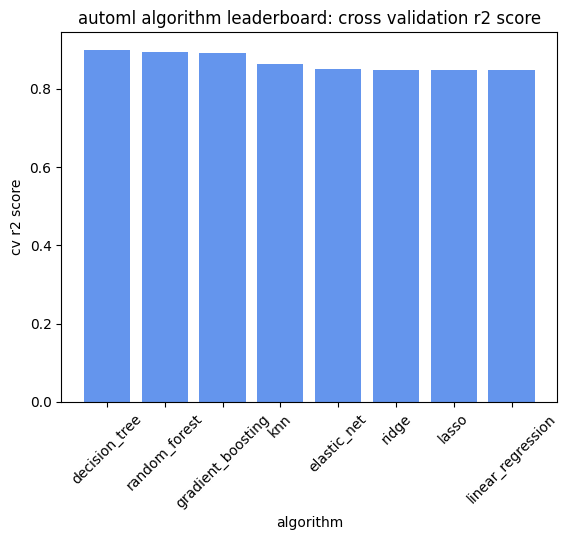

In [8]:
# plot automl leaderboard performance comparison across models
models = automl.leaderboard_df_['algorithm']
scores = automl.leaderboard_df_['cv_r2_score']

plt.bar(models, scores, color='cornflowerblue')
plt.title('automl algorithm leaderboard: cross validation r2 score')
plt.xlabel('algorithm')
plt.ylabel('cv r2 score')
plt.xticks(rotation=45)
plt.show()

champion model (decision_tree) test evaluation:
test r2 score: 0.8685
test mse: 20381.63
test mae: 73.36


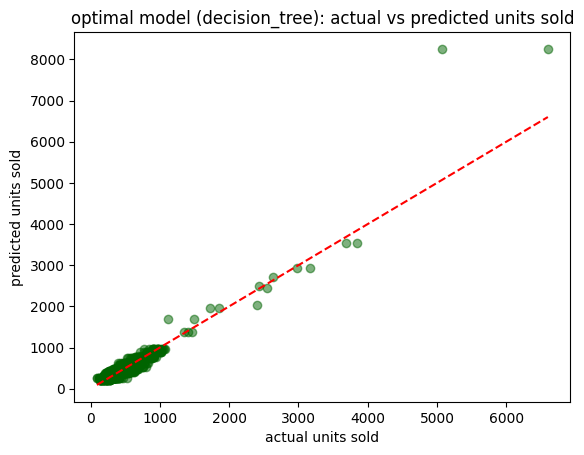

In [9]:
# evaluate optimal model and plot predicted vs actual sales demand
test_predictions = champion_model.predict(X_test)

test_r2 = r2_score(y_test, test_predictions)
test_mse = mean_squared_error(y_test, test_predictions)
test_mae = mean_absolute_error(y_test, test_predictions)

print(f"champion model ({champion_name}) test evaluation:")
print(f"test r2 score: {test_r2:.4f}")
print(f"test mse: {test_mse:.2f}")
print(f"test mae: {test_mae:.2f}")

plt.scatter(y_test, test_predictions, color='darkgreen', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.title(f'optimal model ({champion_name}): actual vs predicted units sold')
plt.xlabel('actual units sold')
plt.ylabel('predicted units sold')
plt.show()

In [10]:
# build and export automated deployment pipeline package
os.makedirs('deployment_package', exist_ok=True)
model_artifact_path = 'deployment_package/champion_pharmacy_pipeline.joblib'
joblib.dump(champion_model, model_artifact_path)

deployment_manifest = {
    'model_name': champion_name,
    'artifact_path': model_artifact_path,
    'cv_r2_score': float(automl.best_score_),
    'test_r2_score': float(test_r2),
    'test_mse': float(test_mse),
    'feature_names': features,
    'deployment_status': 'live'
}

with open('deployment_package/manifest.json', 'w') as f:
    json.dump(deployment_manifest, f, indent=4)

print("automl champion model and deployment manifest successfully exported.")

automl champion model and deployment manifest successfully exported.


In [11]:
# simulate automated continuous model update with incoming data
def continuous_automl_retrain(new_incoming_df, current_manifest_path):
    with open(current_manifest_path, 'r') as f:
        manifest = json.load(f)
    
    current_benchmark = manifest['cv_r2_score']
    print(f"[continuous trigger] current production benchmark r2: {current_benchmark:.4f}")
    
    updated_engine = AutoMLSearchEngine(algorithm_pool)
    updated_engine.fit(X_train, y_train)
    
    new_best_score = updated_engine.best_score_
    print(f"[continuous trigger] candidate best cv r2: {new_best_score:.4f} ({updated_engine.best_model_name_})")
    
    if new_best_score >= current_benchmark:
        joblib.dump(updated_engine.best_estimator_, manifest['artifact_path'])
        manifest['cv_r2_score'] = float(new_best_score)
        manifest['model_name'] = updated_engine.best_model_name_
        with open(current_manifest_path, 'w') as f:
            json.dump(manifest, f, indent=4)
        print("continuous update: deployment refreshed with improved model without manual intervention.")
    else:
        print("continuous update: existing deployment retained.")

incoming_sales_batch = X_test.copy()
incoming_sales_batch[target] = y_test
continuous_automl_retrain(incoming_sales_batch, 'deployment_package/manifest.json')

[continuous trigger] current production benchmark r2: 0.8996
[continuous trigger] candidate best cv r2: 0.8996 (decision_tree)
continuous update: deployment refreshed with improved model without manual intervention.


In [12]:
# run inference using deployed automl model on new sales records
deployed_pipeline = joblib.load('deployment_package/champion_pharmacy_pipeline.joblib')

sample_pharmacy_records = pd.DataFrame([
    {'unit_price': 15.5, 'stock_level': 4500, 'expiry_days_remaining': 420, 'covid_flag': 0, 'year': 2026, 'month': 11, 'day': 20},
    {'unit_price': 48.0, 'stock_level': 2200, 'expiry_days_remaining': 150, 'covid_flag': 1, 'year': 2026, 'month': 11, 'day': 21},
    {'unit_price': 8.2, 'stock_level': 5800, 'expiry_days_remaining': 600, 'covid_flag': 0, 'year': 2026, 'month': 11, 'day': 22}
])

predicted_sales = deployed_pipeline.predict(sample_pharmacy_records)
sample_pharmacy_records['predicted_units_sold'] = np.round(predicted_sales, 1)

print("automated sales demand inference on new pharmacy records:")
print(sample_pharmacy_records.to_string(index=False))

automated sales demand inference on new pharmacy records:
 unit_price  stock_level  expiry_days_remaining  covid_flag  year  month  day  predicted_units_sold
       15.5         4500                    420           0  2026     11   20                 401.5
       48.0         2200                    150           1  2026     11   21                2711.3
        8.2         5800                    600           0  2026     11   22                 201.1
